# **Exercise 1 · Comedy show**

### **ه**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'FreeSerif', 'DejaVu Serif'],
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
})
SKY, SKY_EDGE = '#9AD0EC', '#5BA8D6'
YELLOW, YELLOW_EDGE = '#F8DC75', '#D9B93A'
GRAY = '#8A94A6'

from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import LeaveOneOut

import warnings
warnings.filterwarnings('ignore')

SEED = 42
rng = np.random.default_rng(SEED)

### **Load the data**

In [2]:
df = pd.read_csv('data.csv')
print('Shape:', df.shape)
print('Go counts:', df['Go'].value_counts().to_dict())
df

Shape: (13, 5)
Go counts: {'YES': 7, 'NO': 6}


,Age,Experience,Rank,Nationality,Go
0,36,10,9,UK,NO
1,42,12,4,USA,NO
2,23,4,6,N,NO
3,52,4,4,USA,NO
4,43,21,8,USA,YES
5,44,14,5,UK,NO
6,66,3,7,N,YES
7,35,14,9,UK,YES
8,52,13,7,N,YES
9,35,5,9,N,YES


### **Synthetic data helper**

In [3]:
from sdv.metadata import Metadata
from sdv.single_table import GaussianCopulaSynthesizer

FEATURES = ['Age', 'Experience', 'Rank', 'Nationality_N', 'Nationality_UK', 'Nationality_USA']


def make_synthetic(real, n):
    metadata = Metadata.detect_from_dataframes(data={'comedian': real})
    synthesizer = GaussianCopulaSynthesizer(metadata)
    synthesizer.fit({'comedian': real})
    synthesizer._set_random_state(int(rng.integers(1e9)))
    return synthesizer.sample(num_rows=n)['comedian']


def encode(frame):
    X = pd.get_dummies(frame.drop(columns='Go'), columns=['Nationality'], dtype=int)
    for c in FEATURES:
        if c not in X:
            X[c] = 0
    return X[FEATURES], (frame['Go'] == 'YES').astype(int)

### **Q1 (a) · Augment the data and train a tree**

In [4]:
synthetic = make_synthetic(df, 100)
df_augmented = pd.concat([df, synthetic], ignore_index=True)
print('Rows:', len(df), '->', len(df_augmented))
display(synthetic.head())

Rows: 13 -> 113


,Age,Experience,Rank,Nationality,Go
0,31,15,9,USA,YES
1,47,9,9,UK,YES
2,21,13,8,UK,NO
3,22,5,6,N,YES
4,28,11,6,N,NO


In [5]:
checks = pd.Series({
    'Experience > Age': (synthetic['Experience'] > synthetic['Age']).sum(),
    'Rank outside real range': (~synthetic['Rank'].between(df['Rank'].min(), df['Rank'].max())).sum(),
    'Exact copies of real rows': synthetic.merge(df, how='inner').shape[0],
})
checks.rename('synthetic rows (of 100)').to_frame()

,synthetic rows (of 100)
Experience > Age,0
Rank outside real range,0
Exact copies of real rows,0


In [6]:
X_aug, y_aug = encode(df_augmented)
tree_gini = DecisionTreeClassifier(criterion='gini', random_state=SEED).fit(X_aug, y_aug)
print('Training accuracy (in-sample):', round(tree_gini.score(X_aug, y_aug), 3))
print('Depth:', tree_gini.get_depth(), '| leaves:', tree_gini.get_n_leaves())

Training accuracy (in-sample): 1.0
Depth: 9 | leaves: 35


### **Q1 (a) · Honest evaluation with leave-one-out**

In [7]:
CRITERIA = ['gini', 'entropy']
REPEATS = 10


def loo_accuracy(n_synth=100):
    hits = {(use, c): np.zeros((REPEATS, len(df))) for use in (False, True) for c in CRITERIA}
    for r in range(REPEATS):
        for i, (tr, te) in enumerate(LeaveOneOut().split(df)):
            real_train = df.iloc[tr]
            synth_train = pd.concat([real_train, make_synthetic(real_train, n_synth)], ignore_index=True)
            Xt, yt = encode(df.iloc[te])
            for use, train in ((False, real_train), (True, synth_train)):
                X, y = encode(train)
                for c in CRITERIA:
                    model = DecisionTreeClassifier(criterion=c, random_state=SEED).fit(X, y)
                    hits[(use, c)][r, i] = model.predict(Xt)[0] == yt.iloc[0]
    rows = []
    for (use, c), h in hits.items():
        rows.append({'training data': 'Real + synthetic' if use else 'Real rows only', 'criterion': c,
                     'LOO accuracy': round(h.mean(), 3), 'std over repeats': round(h.mean(axis=1).std(), 3)})
    return pd.DataFrame(rows)


loo_accuracy()

,training data,criterion,LOO accuracy,std over repeats
0,Real rows only,gini,0.846,0.000
1,Real rows only,entropy,0.846,0.000
2,Real + synthetic,gini,0.492,0.134
3,Real + synthetic,entropy,0.446,0.149


### **Q1 (b) · Gini vs entropy**

In [8]:
tree_entropy = DecisionTreeClassifier(criterion='entropy', random_state=SEED).fit(X_aug, y_aug)

summary = pd.DataFrame({
    'depth': [tree_gini.get_depth(), tree_entropy.get_depth()],
    'leaves': [tree_gini.get_n_leaves(), tree_entropy.get_n_leaves()],
    'root split': [FEATURES[tree_gini.tree_.feature[0]], FEATURES[tree_entropy.tree_.feature[0]]],
    'root threshold': [round(tree_gini.tree_.threshold[0], 2), round(tree_entropy.tree_.threshold[0], 2)],
}, index=['gini', 'entropy'])
display(summary)

importance = pd.DataFrame({'gini': tree_gini.feature_importances_,
                           'entropy': tree_entropy.feature_importances_}, index=FEATURES).round(3)
importance

,depth,leaves,root split,root threshold
gini,9,35,Nationality_N,0.5
entropy,10,38,Nationality_N,0.5


,gini,entropy
Age,0.406,0.386
Experience,0.287,0.316
Rank,0.201,0.209
Nationality_N,0.062,0.051
Nationality_UK,0.044,0.038
Nationality_USA,0.000,0.000


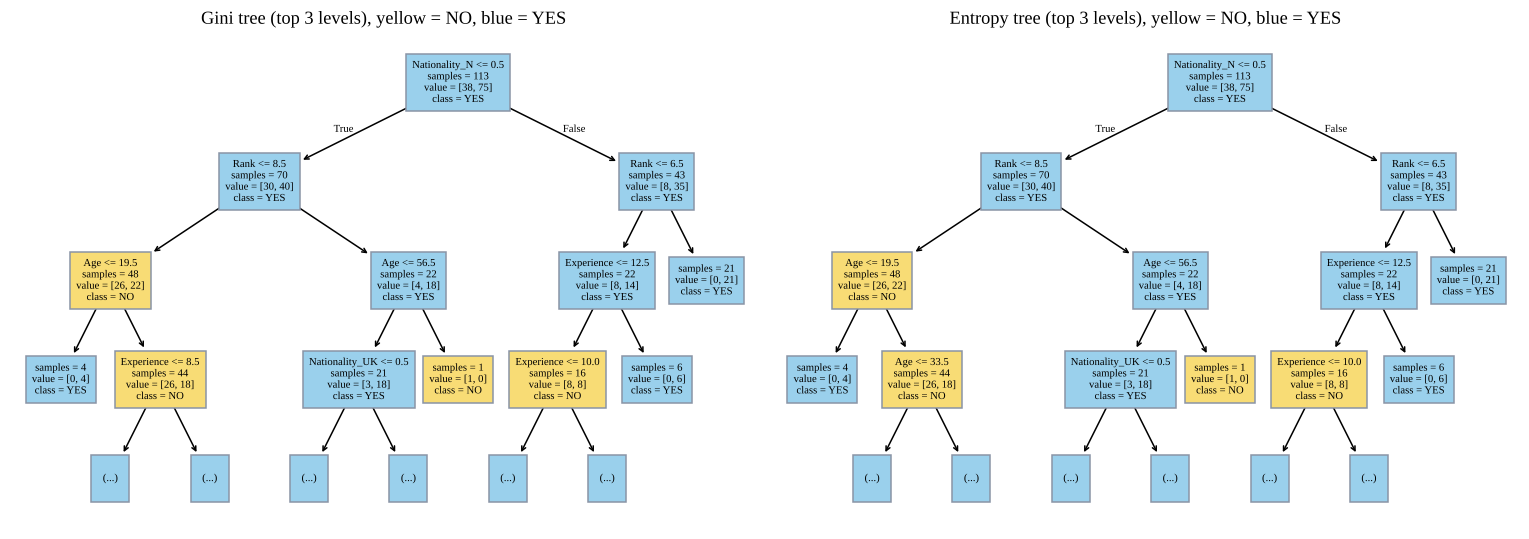

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, model, title in zip(axes, [tree_gini, tree_entropy], ['Gini', 'Entropy']):
    plot_tree(model, feature_names=FEATURES, class_names=['NO', 'YES'], filled=True, max_depth=3,
              impurity=False, ax=ax, fontsize=7)
    for t in ax.texts:
        patch = t.get_bbox_patch()
        if patch is not None:
            patch.set_facecolor(YELLOW if t.get_text().rstrip().endswith('NO') else SKY)
            patch.set_edgecolor(GRAY)
    ax.set_title(f'{title} tree (top 3 levels), yellow = NO, blue = YES')
plt.tight_layout()
plt.show()

In [10]:
runs = []
for _ in range(30):
    aug = pd.concat([df, make_synthetic(df, 100)], ignore_index=True)
    X, y = encode(aug)
    for crit in ['gini', 'entropy']:
        m = DecisionTreeClassifier(criterion=crit, random_state=SEED).fit(X, y)
        row = {'criterion': crit, 'depth': m.get_depth(), 'leaves': m.get_n_leaves(),
               'root': FEATURES[m.tree_.feature[0]]}
        row.update(dict(zip(FEATURES, m.feature_importances_)))
        runs.append(row)
runs = pd.DataFrame(runs)
display(runs.groupby('criterion')[['depth', 'leaves']].agg(['mean', 'std']).round(2))
display(runs.groupby('criterion')[FEATURES].mean().round(3))
pd.crosstab(runs['criterion'], runs['root'])

depth       leaves      
            mean   std   mean   std
criterion                          
entropy    13.30  2.42  43.03  5.16
gini       12.07  1.84  42.67  4.59

,Age,Experience,Rank,Nationality_N,Nationality_UK,Nationality_USA
criterion,,,,,,
entropy,0.432,0.293,0.169,0.041,0.032,0.033
gini,0.409,0.306,0.178,0.040,0.031,0.036


root,Age,Experience,Nationality_N,Nationality_USA,Rank
criterion,,,,,
entropy,2,13,1,1,13
gini,3,11,1,2,13
